# 03 - Bias: hangt het oordeel samen met wat er in de wedstrijd gebeurde?

Voor 59 gescoute wedstrijden is er eventdata (SciSports, `data/scouting_bias_sample/`). Dit notebook kijkt of het oordeel van de scout (`performance` en `potential`) samenhangt met wat er in die wedstrijd gebeurde.

**Alleen kengetallen die op zich iets zeggen.** Absolute tellingen zoals het aantal tackles of passes zijn zonder vergelijking met een hele competitie niet te interpreteren, dus die blijven weg. Wel gebruikt:

| Groep | Kengetal |
|---|---|
| Uitslag (iedereen) | resultaat (winst/gelijk/verlies), doelsaldo |
| Keepers | tegendoelpunten, clean sheet, doelpunten eigen ploeg, reddingspercentage, *goals prevented* (post-shot xG − tegendoelpunten), passpercentage |
| Verdedigers (CB, LB, RB) | tegendoelpunten, clean sheet, pass- en duelpercentage |
| Aanvallers (CAM, LW, RW, ST, CF) | doelpunten, assists, doelpunt of assist, pass- en dribbelpercentage |
| Middenvelders (CDM, CM) | doelpunt of assist, pass- en duelpercentage |

**Twee correlaties per kengetal**
- **Spearman $\rho$:** de ruwe rangcorrelatie over alle rapporten.
- **Binnen scouts:** Pearson-correlatie nadat het gemiddelde van elke scout van zowel het oordeel als het kengetal is afgetrokken. Een milde scout die toevallig sterke ploegen ziet, maakt dan geen verband. Scouts met minder dan 3 rapporten in de groep tellen hier niet mee.

Dit blijft aan de kant van de scout. De eventdata is geen criterium $Y_e$ (een goede keeper krijgt ook echt minder doelpunten), maar dient om te zien welke informatie samenhangt met het oordeel. Het zijn correlaties, geen bewijs van oorzaak.

## 1. Data

In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

CLEAN_DIR = Path("data") / "clean"
EVENT_DIR = Path("data") / "scouting_bias_sample" / "scouting_bias_sample"

# Minimum aantal pogingen in de wedstrijd voor een succespercentage
MIN_PASSES, MIN_DUELS, MIN_DRIBBLES, MIN_SHOTS_ON_TARGET = 10, 3, 2, 2
MIN_REPORTS_WITHIN_SCOUT = 3

pd.set_option("display.max_columns", None, "display.max_rows", 100)

BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "xtick.bottom": False, "ytick.left": False,
    "legend.frameon": False,
})

In [27]:
matches = pd.read_csv(EVENT_DIR / "matches.csv")
squads = pd.read_csv(EVENT_DIR / "squads.csv")
events = pd.read_csv(EVENT_DIR / "events.csv", low_memory=False)
events = events.sort_values(["match_id", "period", "event_order"]).reset_index(drop=True)

reports = pd.read_csv(CLEAN_DIR / "reports_clean.csv", encoding="utf-8-sig")
reports = reports[reports["is_usable"] & reports["match_id"].isin(matches["scouting_match_id"])].copy()

# Koppel elk rapport aan de speler in de SciSports-opstelling (ids zijn uniek binnen een wedstrijd)
link = (
    squads.dropna(subset=["scouting_player_id"])
    .astype({"scouting_player_id": int})
    .rename(columns={"scouting_match_id": "match_id", "scouting_player_id": "player_id",
                     "match_id": "sci_match_id", "player_id": "sci_player_id", "team_id": "sci_team_id"})
    [["match_id", "player_id", "sci_match_id", "sci_player_id", "sci_team_id", "minutes_played"]]
)
reports = reports.merge(link, on=["match_id", "player_id"], how="left")

print(f"{matches['scouting_match_id'].nunique()} wedstrijden, {len(reports)} bruikbare rapporten")
print(f"  niet gekoppeld aan de opstelling: {reports['sci_player_id'].isna().sum()}")
print(f"  keepers: {reports['is_goalkeeper'].sum()}, veldspelers: {(~reports['is_goalkeeper']).sum()}")

59 wedstrijden, 138 bruikbare rapporten
  niet gekoppeld aan de opstelling: 1
  keepers: 37, veldspelers: 101


**Uitslag.** In `matches.csv` staan twee wedstrijden ten onrechte op 0-0: `scouting_match_id` 258 en 1419. De doelpunten in de events komen wel overeen met de uitslag op het scoutingplatform. Daarom gebruikt dit notebook de uitslag uit `reports_clean.csv`.

In [28]:
goal_shots = events[(events["event_type"] == "shot") & events["outcome_type"].isin(["successful", "own_goal"])]
event_score = goal_shots.groupby(["match_id", "team_id"]).size().unstack(fill_value=0)
check = matches.set_index("match_id")[["scouting_match_id", "home_team_id", "away_team_id"]].copy()
check["home_events"] = [event_score.loc[m].get(t, 0) if m in event_score.index else 0
                        for m, t in zip(check.index, check["home_team_id"])]
check["away_events"] = [event_score.loc[m].get(t, 0) if m in event_score.index else 0
                        for m, t in zip(check.index, check["away_team_id"])]
platform = reports.drop_duplicates("match_id").set_index("match_id")[["home_score", "away_score"]]
check = check.join(platform, on="scouting_match_id")
mismatch = check[(check["home_events"] != check["home_score"]) | (check["away_events"] != check["away_score"])]
print(f"Wedstrijden waar events en platform verschillen: {len(mismatch)}")

Wedstrijden waar events en platform verschillen: 0


## 2. Kengetallen per rapport

In [29]:
side = np.where(reports["player_side"] == "home", 1, -1)
reports["goal_diff"] = (reports["home_score"] - reports["away_score"]) * side
reports["result"] = np.sign(reports["goal_diff"])  # 1 = winst, 0 = gelijk, -1 = verlies
reports["goals_for"] = np.where(side == 1, reports["home_score"], reports["away_score"])
reports["goals_conceded"] = np.where(side == 1, reports["away_score"], reports["home_score"])
reports["clean_sheet"] = (reports["goals_conceded"] == 0).astype(int)

key = ["match_id", "player_id"]
shots = events[events["event_type"] == "shot"]
goals = shots[shots["outcome_type"] == "successful"]  # eigen doelpunten tellen niet voor de speler


def find_assists(events, goals):
    """Laatste geslaagde pass naar de doelpuntenmaker in hetzelfde balbezit (eigen carries overgeslagen)."""
    found = []
    for idx, shot in goals.iterrows():
        j = idx - 1
        while j >= 0 and events.at[j, "match_id"] == shot["match_id"] \
                and events.at[j, "possession_sequence_id"] == shot["possession_sequence_id"]:
            event = events.loc[j]
            if event["event_type"] == "carry" and event["player_id"] == shot["player_id"]:
                j -= 1
                continue
            if event["event_type"] == "pass" and event["receiver_id"] == shot["player_id"] \
                    and event["player_id"] != shot["player_id"]:
                found.append((event["match_id"], event["player_id"]))
            break
    return pd.DataFrame(found, columns=key).groupby(key).size().rename("assists")


def success_counts(df, ok, valid, prefix):
    df = df[df["outcome_type"].isin(valid)]
    return df.groupby(key).agg(**{f"n_{prefix}": ("outcome_type", "size"),
                                  f"{prefix}_ok": ("outcome_type", lambda x: x.isin(ok).sum())})


per_player = pd.concat([
    goals.groupby(key).size().rename("goals"),
    find_assists(events, goals),
    success_counts(events[events["event_type"] == "pass"], ["successful"],
                   ["successful", "intercepted", "out_of_play", "offside"], "passes"),
    success_counts(events[events["event_type"] == "duel"], ["won"], ["won", "lost"], "duels"),
    success_counts(events[events["event_type"] == "dribble"], ["successful"], ["successful", "unsuccessful"], "dribbles"),
], axis=1).fillna(0).reset_index().rename(columns={"match_id": "sci_match_id", "player_id": "sci_player_id"})

reports = reports.merge(per_player, on=["sci_match_id", "sci_player_id"], how="left")
count_cols = ["goals", "assists", "n_passes", "passes_ok", "n_duels", "duels_ok", "n_dribbles", "dribbles_ok"]
reports[count_cols] = reports[count_cols].fillna(0)
reports["goal_or_assist"] = ((reports["goals"] + reports["assists"]) > 0).astype(int)


def pct(ok, n, minimum):
    return np.where(n >= minimum, ok / n.where(n > 0), np.nan)


reports["pass_pct"] = pct(reports["passes_ok"], reports["n_passes"], MIN_PASSES)
reports["duel_pct"] = pct(reports["duels_ok"], reports["n_duels"], MIN_DUELS)
reports["dribble_pct"] = pct(reports["dribbles_ok"], reports["n_dribbles"], MIN_DRIBBLES)
print(f"Doelpunten in alle events: {len(goals)}")
print(f"Bij de gescoute veldspelers: {reports['goals'].sum():.0f} doelpunten, {reports['assists'].sum():.0f} assists")

Doelpunten in alle events: 225
Bij de gescoute veldspelers: 13 doelpunten, 9 assists


**Keepers.** De schoten op doel van de tegenstander zijn de geredde schoten plus de doelpunten (zonder eigen doelpunten). Daaruit volgt:
- **Reddingspercentage:** geredde schoten / schoten op doel, met minstens 2 schoten op doel.
- **Goals prevented:** de som van de post-shot xG van die schoten min het aantal tegendoelpunten. Positief betekent minder doelpunten dan verwacht op basis van de schoten.

Alle gescoute keepers stonden 81 minuten of meer op het veld, dus de tellingen per ploeg gelden voor de keeper.

In [30]:
on_target = shots[shots["outcome_type"].isin(["saved", "successful"])]
faced = on_target.groupby(["match_id", "team_id"]).agg(
    shots_on_target=("outcome_type", "size"),
    saved=("outcome_type", lambda x: (x == "saved").sum()),
    psxg_faced=("vendor_post_shot_xg", "sum"),
).reset_index().merge(matches[["match_id", "home_team_id", "away_team_id"]], on="match_id")
# Toewijzen aan de verdedigende ploeg
faced["sci_team_id"] = np.where(faced["team_id"] == faced["home_team_id"], faced["away_team_id"], faced["home_team_id"])
faced = faced.rename(columns={"match_id": "sci_match_id"})[["sci_match_id", "sci_team_id", "shots_on_target", "saved", "psxg_faced"]]

reports = reports.merge(faced, on=["sci_match_id", "sci_team_id"], how="left")
reports[["shots_on_target", "saved", "psxg_faced"]] = reports[["shots_on_target", "saved", "psxg_faced"]].fillna(0)
reports["save_pct"] = pct(reports["saved"], reports["shots_on_target"], MIN_SHOTS_ON_TARGET)
reports["goals_prevented"] = reports["psxg_faced"] - (reports["shots_on_target"] - reports["saved"])

keepers = reports[reports["is_goalkeeper"]]
print(f"Keeperrapporten: {len(keepers)}, scouts: {keepers['scout_id'].value_counts().to_dict()}")
print(f"Minuten keepers: min {keepers['minutes_played'].min():.0f}")
keepers[["goals_conceded", "clean_sheet", "save_pct", "goals_prevented", "pass_pct", "performance", "potential"]].describe().round(2)

Keeperrapporten: 37, scouts: {22: 31, 21: 5, 37: 1}
Minuten keepers: min 81


,goals_conceded,clean_sheet,save_pct,goals_prevented,pass_pct,performance,potential
count,37.00,37.00,34.00,37.00,37.00,37.00,33.00
mean,1.65,0.24,0.67,-0.21,0.78,2.14,2.79
std,1.40,0.43,0.21,0.88,0.12,0.82,0.60
min,0.00,0.00,0.25,-2.64,0.44,1.00,2.00
25%,1.00,0.00,0.50,-0.64,0.71,2.00,2.00
50%,2.00,0.00,0.63,-0.20,0.80,2.00,3.00
75%,2.00,0.00,0.82,0.29,0.86,3.00,3.00
max,5.00,1.00,1.00,2.30,0.97,4.00,4.00


## 3. Correlaties

In [31]:
POSITION_GROUPS = {
    "Keepers": ["GK"],
    "Verdedigers": ["CB", "LB", "RB"],
    "Middenvelders": ["CDM", "CM"],
    "Aanvallers": ["CAM", "LW", "RW", "ST", "CF"],
}
METRICS = {
    "Keepers": ["result", "goal_diff", "goals_for", "goals_conceded", "clean_sheet",
                "save_pct", "goals_prevented", "pass_pct"],
    "Verdedigers": ["result", "goal_diff", "goals_conceded", "clean_sheet", "pass_pct", "duel_pct"],
    "Middenvelders": ["result", "goal_diff", "goal_or_assist", "pass_pct", "duel_pct"],
    "Aanvallers": ["result", "goal_diff", "goals", "assists", "goal_or_assist", "pass_pct", "dribble_pct"],
}
LABELS = {
    "result": "Resultaat (W/G/V)", "goal_diff": "Doelsaldo", "goals_for": "Doelpunten eigen ploeg",
    "goals_conceded": "Tegendoelpunten", "clean_sheet": "Clean sheet", "save_pct": "Reddingspercentage",
    "goals_prevented": "Goals prevented", "pass_pct": "Passpercentage", "duel_pct": "Duelpercentage",
    "dribble_pct": "Dribbelpercentage", "goals": "Doelpunten", "assists": "Assists",
    "goal_or_assist": "Doelpunt of assist",
}


def correlate(df, metric, judgement):
    d = df[[metric, judgement, "scout_id"]].dropna()
    row = {"n": len(d), "spearman": np.nan, "p": np.nan, "binnen_scouts": np.nan, "p_binnen": np.nan, "n_binnen": 0}
    if len(d) < 8 or d[metric].nunique() < 2:
        return row
    row["spearman"], row["p"] = stats.spearmanr(d[metric], d[judgement])
    sizes = d.groupby("scout_id")[judgement].transform("size")
    w = d[sizes >= MIN_REPORTS_WITHIN_SCOUT]
    centred = w[[metric, judgement]] - w.groupby("scout_id")[[metric, judgement]].transform("mean")
    row["n_binnen"] = len(w)
    if len(w) >= 8 and centred[metric].std() > 0:
        row["binnen_scouts"], row["p_binnen"] = stats.pearsonr(centred[metric], centred[judgement])
    return row


rows = []
for group, positions in POSITION_GROUPS.items():
    df = reports[reports["questionnaire_position"].isin(positions)]
    for judgement in ["performance", "potential"]:
        for metric in METRICS[group]:
            rows.append({"groep": group, "oordeel": judgement, "kengetal": LABELS[metric],
                         **correlate(df, metric, judgement)})
results = pd.DataFrame(rows)

# Correctie voor meerdere toetsen (Benjamini-Hochberg over alle toetsen)
valid = results["p"].notna()
results.loc[valid, "q"] = multipletests(results.loc[valid, "p"], method="fdr_bh")[1]
print(reports.groupby(reports["questionnaire_position"].map(
    {p: g for g, ps in POSITION_GROUPS.items() for p in ps})).size().to_dict())

{'Aanvallers': 45, 'Keepers': 37, 'Middenvelders': 25, 'Verdedigers': 31}


`p` is de gewone p-waarde van de Spearman-correlatie. `q` corrigeert voor het grote aantal toetsen (Benjamini-Hochberg). Bij zoveel correlaties zijn er altijd een paar met p < 0.05 door toeval. Kijk dus vooral naar wat ook na correctie overeind blijft, en naar wat in beide kolommen (ruw en binnen scouts) dezelfde richting heeft.

### 3.1 Overzicht als matrix

Elke cel is de correlatie tussen een kengetal (rij) en het oordeel, per positiegroep (kolom). Blauw betekent positief (hoger kengetal, hoger oordeel), rood negatief, grijs geen verband. Een lege cel betekent dat het kengetal niet bekeken is voor die groep.

- `*` p < 0.05
- `**` ook na correctie voor meerdere toetsen (q < 0.05)

De eerste figuur toont de ruwe Spearman-correlaties. De tweede toont de correlaties binnen scouts, waar de verschillen in strengheid tussen scouts eruit zijn.

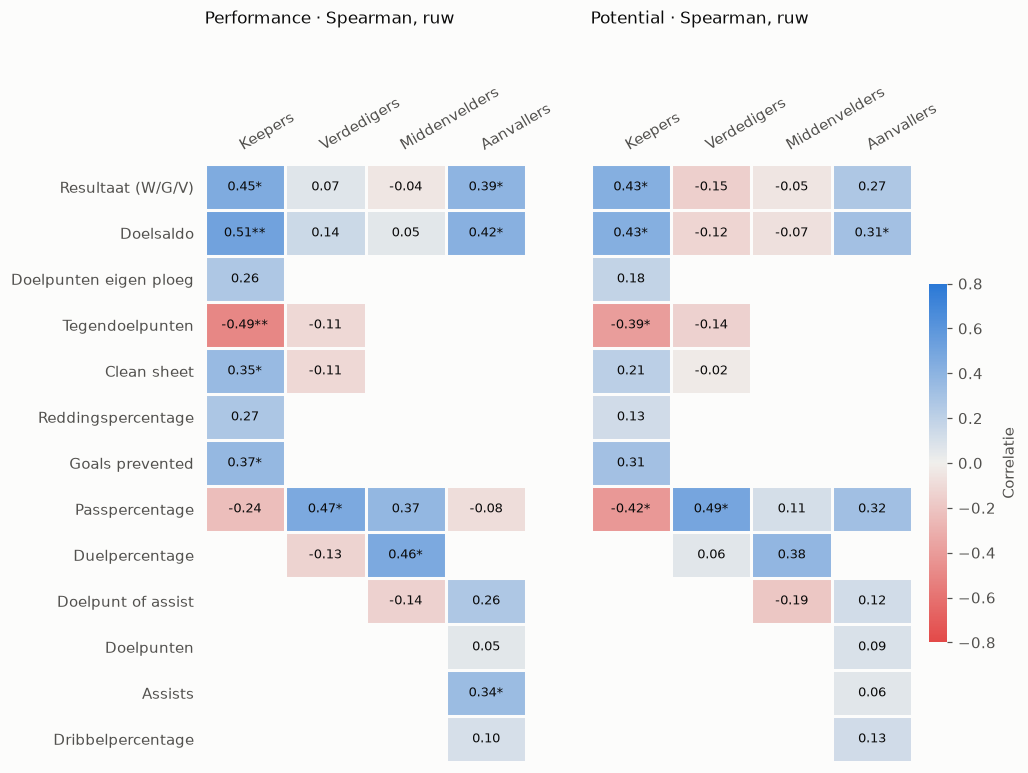

In [32]:
from matplotlib.colors import LinearSegmentedColormap

# Divergerend: rood (negatief) - neutraal grijs - blauw (positief)
DIVERGING = LinearSegmentedColormap.from_list("rood_blauw", ["#e34948", "#f0efec", "#2a78d6"])
GROUPS = list(POSITION_GROUPS)
METRIC_ORDER = [LABELS[m] for m in dict.fromkeys(m for g in GROUPS for m in METRICS[g])]


def draw_matrix(ax, data, title, row_labels, col_labels, stars=None, vmax=0.8):
    ax.imshow(np.ma.masked_invalid(data), cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_facecolor(SURFACE)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if np.isnan(data[i, j]):
                continue
            mark = "" if stars is None else stars[i][j]
            ax.text(j, i, f"{data[i, j]:.2f}{mark}", ha="center", va="center", fontsize=8.5, color=INK)
    ax.set_xticks(range(len(col_labels)), col_labels)
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.tick_params(axis="x", labeltop=True, labelbottom=False)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="left", rotation_mode="anchor")
    # 2px witte scheiding tussen de cellen
    ax.set_xticks(np.arange(-0.5, len(col_labels)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_labels)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, pad=40)


def correlation_matrix(value_col, p_col, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.42 * len(METRIC_ORDER) + 1.6), sharey=True)
    for ax, judgement in zip(axes, ["performance", "potential"]):
        table = results[results["oordeel"] == judgement]
        values = table.pivot(index="kengetal", columns="groep", values=value_col).reindex(index=METRIC_ORDER, columns=GROUPS)
        pvals = table.pivot(index="kengetal", columns="groep", values=p_col).reindex(index=METRIC_ORDER, columns=GROUPS)
        qvals = table.pivot(index="kengetal", columns="groep", values="q").reindex(index=METRIC_ORDER, columns=GROUPS)
        stars = [["**" if (value_col == "spearman" and q < 0.05) else "*" if p < 0.05 else ""
                  for p, q in zip(pr, qr)] for pr, qr in zip(pvals.to_numpy(), qvals.to_numpy())]
        draw_matrix(ax, values.to_numpy(dtype=float), f"{judgement.capitalize()} · {title}", METRIC_ORDER, GROUPS, stars)
    sm_ = plt.cm.ScalarMappable(cmap=DIVERGING, norm=plt.Normalize(-0.8, 0.8))
    cbar = fig.colorbar(sm_, ax=axes, shrink=0.6, pad=0.02)
    cbar.outline.set_visible(False)
    cbar.set_label("Correlatie")
    plt.show()


correlation_matrix("spearman", "p", "Spearman, ruw")

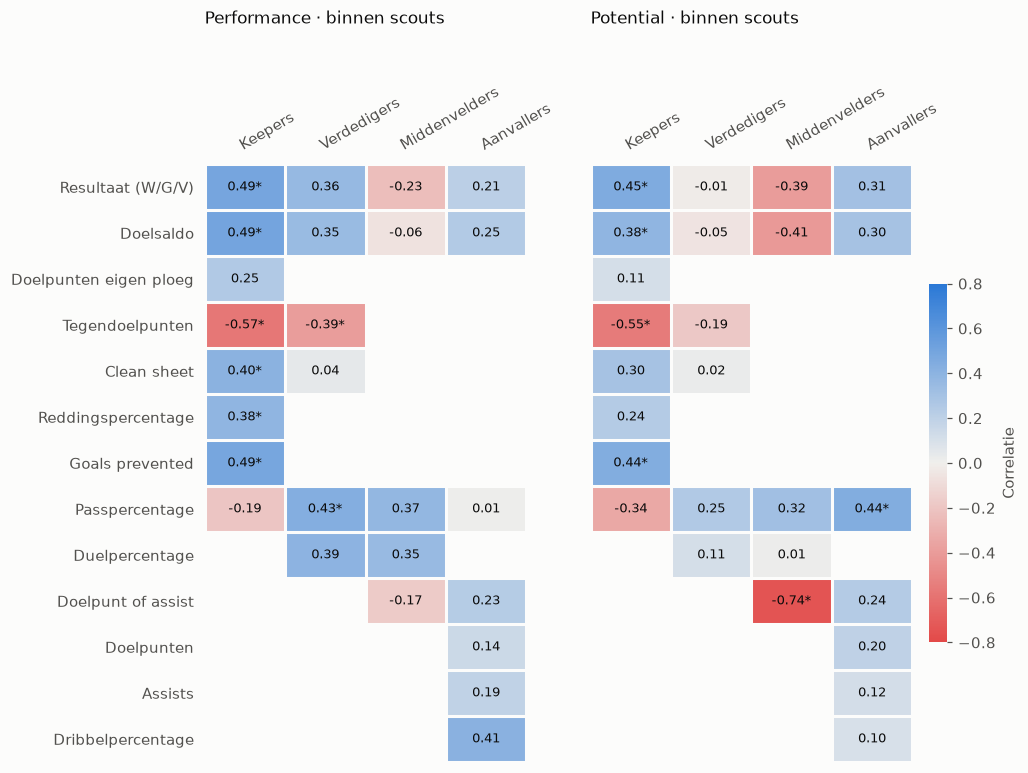

In [33]:
correlation_matrix("binnen_scouts", "p_binnen", "binnen scouts")


### 3.2 Tabellen per groep

Dezelfde cijfers als in de matrices, met de aantallen en p-waarden erbij.

In [34]:
def show(group):
    table = results[results["groep"] == group].drop(columns="groep").set_index(["oordeel", "kengetal"])
    return table.round(3)


show("Keepers")

n  spearman      p  binnen_scouts  \
oordeel     kengetal                                                     
performance Resultaat (W/G/V)       37     0.454  0.005          0.494   
            Doelsaldo               37     0.509  0.001          0.494   
            Doelpunten eigen ploeg  37     0.264  0.114          0.254   
            Tegendoelpunten         37    -0.494  0.002         -0.573   
            Clean sheet             37     0.351  0.033          0.404   
            Reddingspercentage      34     0.271  0.121          0.385   
            Goals prevented         37     0.368  0.025          0.486   
            Passpercentage          37    -0.236  0.160         -0.194   
potential   Resultaat (W/G/V)       33     0.430  0.012          0.452   
            Doelsaldo               33     0.430  0.012          0.381   
            Doelpunten eigen ploeg  33     0.181  0.312          0.111   
            Tegendoelpunten         33    -0.392  0.024         -0.552   
            Clean sheet             33     0.210  0.240          0.299   
            Reddingspercentage      30     0.126  0.506          0.244   
            Goals prevented         33     0.311  0.078          0.442   
            Passpercentage          33    -0.419  0.015         -0.340   

                                    p_binnen  n_binnen      q  
oordeel     kengetal                                           
performance Resultaat (W/G/V)          0.002        36  0.061  
            Doelsaldo                  0.002        36  0.049  
            Doelpunten eigen ploeg     0.135        36  0.257  
            Tegendoelpunten            0.000        36  0.049  
            Clean sheet                0.015        36  0.123  
            Reddingspercentage         0.027        33  0.261  
            Goals prevented            0.003        36  0.100  
            Passpercentage             0.256        36  0.333  
potential   Resultaat (W/G/V)          0.009        32  0.072  
            Doelsaldo                  0.031        32  0.072  
            Doelpunten eigen ploeg     0.545        32  0.601  
            Tegendoelpunten            0.001        32  0.100  
            Clean sheet                0.097        32  0.481  
            Reddingspercentage         0.203        29  0.770  
            Goals prevented            0.011        32  0.212  
            Passpercentage             0.057        32  0.080

In [35]:
show("Verdedigers")

n  spearman      p  binnen_scouts  p_binnen  \
oordeel     kengetal                                                          
performance Resultaat (W/G/V)  31     0.068  0.718          0.362     0.058   
            Doelsaldo          31     0.145  0.437          0.349     0.069   
            Tegendoelpunten    31    -0.108  0.562         -0.388     0.041   
            Clean sheet        31    -0.110  0.556          0.040     0.840   
            Passpercentage     30     0.467  0.009          0.435     0.023   
            Duelpercentage     17    -0.133  0.611          0.395     0.259   
potential   Resultaat (W/G/V)  27    -0.152  0.448         -0.014     0.949   
            Doelsaldo          27    -0.120  0.552         -0.051     0.818   
            Tegendoelpunten    27    -0.139  0.488         -0.186     0.395   
            Clean sheet        27    -0.024  0.906          0.022     0.919   
            Passpercentage     26     0.488  0.011          0.254     0.254   
            Duelpercentage     16     0.061  0.821          0.108     0.766   

                               n_binnen      q  
oordeel     kengetal                            
performance Resultaat (W/G/V)        28  0.811  
            Doelsaldo                28  0.753  
            Tegendoelpunten          28  0.770  
            Clean sheet              28  0.770  
            Passpercentage           27  0.072  
            Duelpercentage           10  0.783  
potential   Resultaat (W/G/V)        23  0.753  
            Doelsaldo                23  0.770  
            Tegendoelpunten          23  0.770  
            Clean sheet              23  0.906  
            Passpercentage           22  0.072  
            Duelpercentage           10  0.853

In [36]:
show("Middenvelders")

n  spearman      p  binnen_scouts  p_binnen  \
oordeel     kengetal                                                           
performance Resultaat (W/G/V)   25    -0.044  0.836         -0.234     0.335   
            Doelsaldo           25     0.051  0.808         -0.059     0.809   
            Doelpunt of assist  25    -0.138  0.509         -0.175     0.474   
            Passpercentage      25     0.372  0.067          0.373     0.116   
            Duelpercentage      20     0.463  0.040          0.350     0.184   
potential   Resultaat (W/G/V)   24    -0.047  0.829         -0.395     0.130   
            Doelsaldo           24    -0.074  0.733         -0.409     0.116   
            Doelpunt of assist  24    -0.193  0.366         -0.742     0.001   
            Passpercentage      24     0.112  0.602          0.319     0.229   
            Duelpercentage      19     0.378  0.111          0.013     0.968   

                                n_binnen      q  
oordeel     kengetal                             
performance Resultaat (W/G/V)         19  0.853  
            Doelsaldo                 19  0.853  
            Doelpunt of assist        19  0.770  
            Passpercentage            19  0.194  
            Duelpercentage            16  0.138  
potential   Resultaat (W/G/V)         16  0.853  
            Doelsaldo                 16  0.811  
            Doelpunt of assist        16  0.679  
            Passpercentage            16  0.783  
            Duelpercentage            13  0.257

In [37]:
show("Aanvallers")

n  spearman      p  binnen_scouts  p_binnen  \
oordeel     kengetal                                                           
performance Resultaat (W/G/V)   45     0.391  0.008          0.212     0.172   
            Doelsaldo           45     0.418  0.004          0.246     0.112   
            Doelpunten          45     0.055  0.720          0.144     0.358   
            Assists             45     0.341  0.022          0.188     0.227   
            Doelpunt of assist  45     0.263  0.081          0.231     0.136   
            Passpercentage      40    -0.081  0.618          0.007     0.969   
            Dribbelpercentage   18     0.103  0.685          0.408     0.147   
potential   Resultaat (W/G/V)   41     0.266  0.093          0.310     0.055   
            Doelsaldo           41     0.310  0.048          0.299     0.064   
            Doelpunten          41     0.093  0.563          0.195     0.233   
            Assists             41     0.062  0.699          0.117     0.478   
            Doelpunt of assist  41     0.122  0.449          0.239     0.143   
            Passpercentage      37     0.318  0.055          0.443     0.008   
            Dribbelpercentage   15     0.129  0.647          0.099     0.773   

                                n_binnen      q  
oordeel     kengetal                             
performance Resultaat (W/G/V)         43  0.072  
            Doelsaldo                 43  0.061  
            Doelpunten                43  0.811  
            Assists                   43  0.100  
            Doelpunt of assist        43  0.212  
            Passpercentage            38  0.783  
            Dribbelpercentage         14  0.811  
potential   Resultaat (W/G/V)         39  0.230  
            Doelsaldo                 39  0.157  
            Doelpunten                39  0.770  
            Assists                   39  0.811  
            Doelpunt of assist        39  0.753  
            Passpercentage            35  0.168  
            Dribbelpercentage         11  0.801

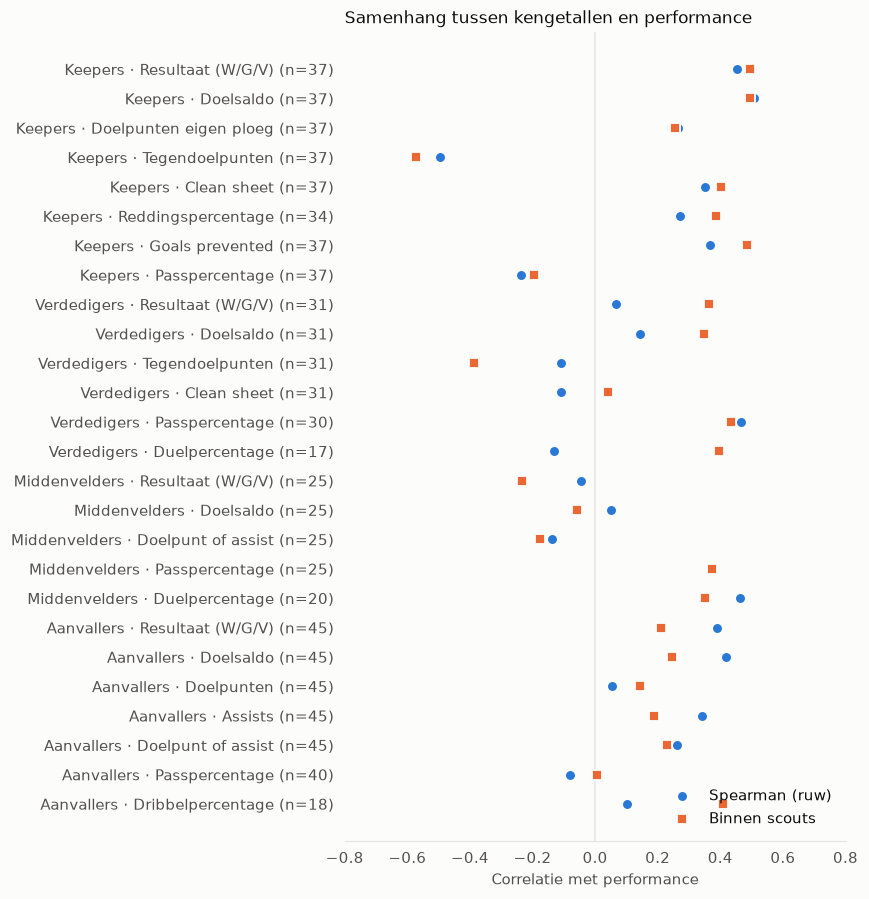

In [38]:
plot = results[results["oordeel"] == "performance"].dropna(subset=["spearman"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.28 * len(plot) + 1))
y = np.arange(len(plot))
ax.axvline(0, color=GRID, linewidth=1)
ax.scatter(plot["spearman"], y, s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.2, label="Spearman (ruw)", zorder=3)
ax.scatter(plot["binnen_scouts"], y, s=50, marker="s", color=ORANGE, edgecolor=SURFACE, linewidth=1.2,
           label="Binnen scouts", zorder=3)
ax.set_yticks(y, [f"{g} · {k} (n={n})" for g, k, n in zip(plot["groep"], plot["kengetal"], plot["n"])])
ax.set_xlim(-0.8, 0.8)
ax.set_xlabel("Correlatie met performance")
ax.spines["left"].set_visible(False)
ax.set_title("Samenhang tussen kengetallen en performance")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 3.3 Samenhang tussen de kengetallen zelf

Per groep een volledige correlatiematrix (Spearman), met het oordeel onderaan. Die laat zien welke kengetallen eigenlijk hetzelfde meten. Tegendoelpunten en goals prevented hangen bij keepers bijvoorbeeld sterk samen. Hun verbanden met het oordeel zijn dus niet onafhankelijk van elkaar.

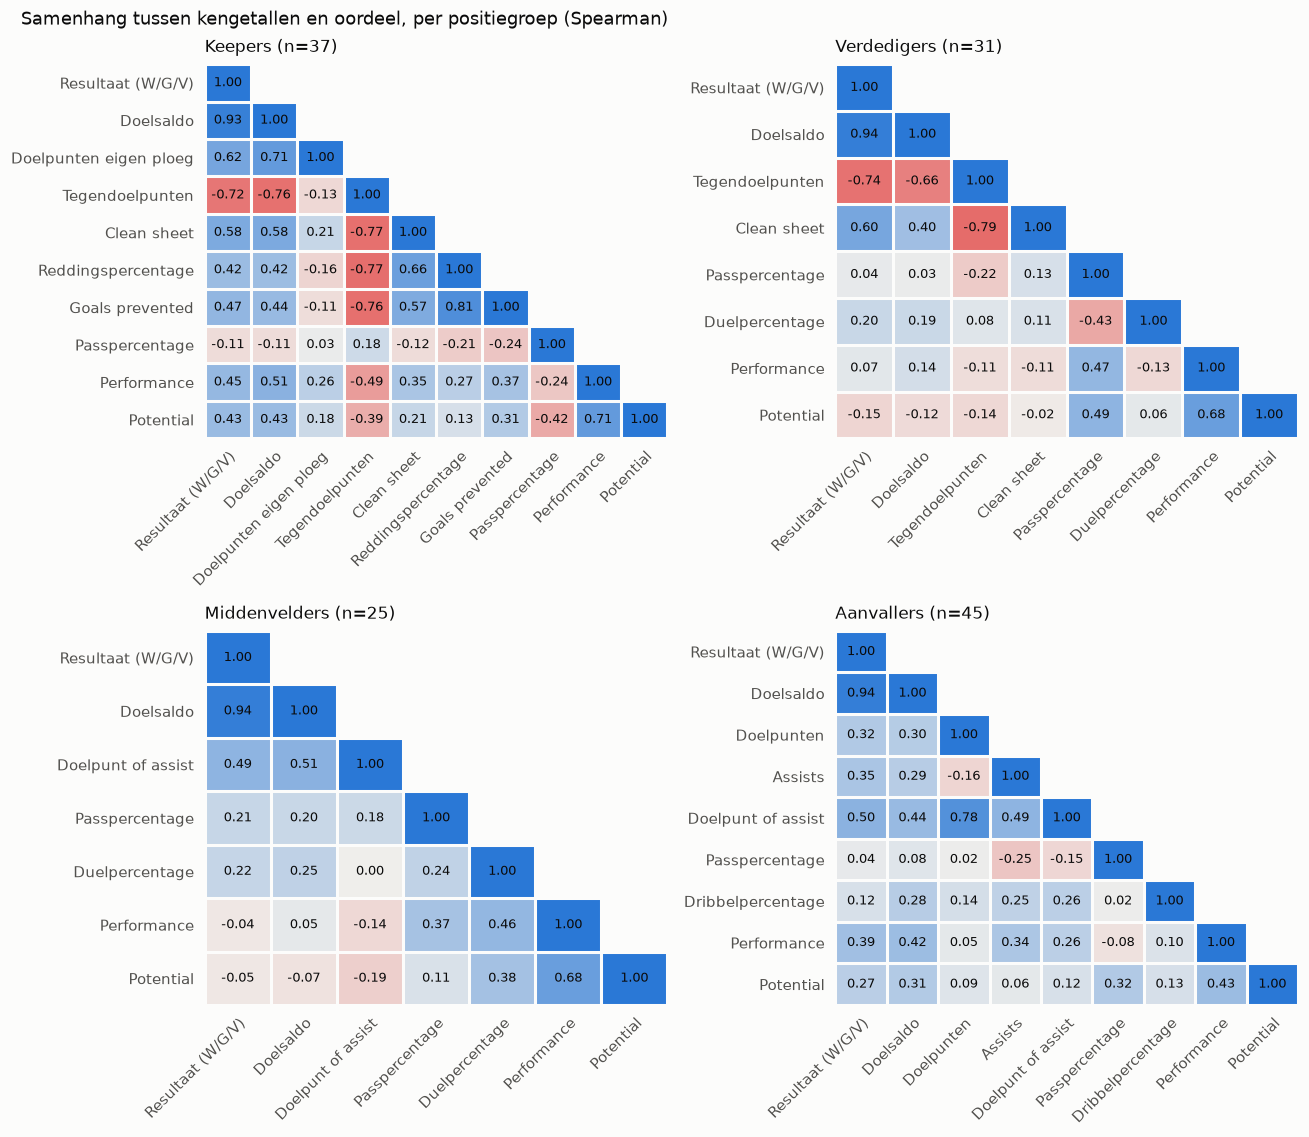

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))
for ax, group in zip(axes.flat, GROUPS):
    cols = METRICS[group] + ["performance", "potential"]
    df = reports[reports["questionnaire_position"].isin(POSITION_GROUPS[group])][cols]
    corr = df.corr(method="spearman").to_numpy(copy=True)
    corr[np.triu_indices_from(corr, k=1)] = np.nan  # alleen de onderste driehoek
    names = [LABELS.get(c, c.capitalize()) for c in cols]
    draw_matrix(ax, corr, f"{group} (n={len(df)})", names, names, vmax=1)
    ax.tick_params(axis="x", labeltop=False, labelbottom=True)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    ax.set_title(f"{group} (n={len(df)})", pad=8)
fig.suptitle("Samenhang tussen kengetallen en oordeel, per positiegroep (Spearman)", x=0.02, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

### 3.4 Oordeel per uitslag

Gemiddelde performance na verlies, gelijkspel en winst, per positiegroep. Het getal boven elke staaf is het aantal rapporten.

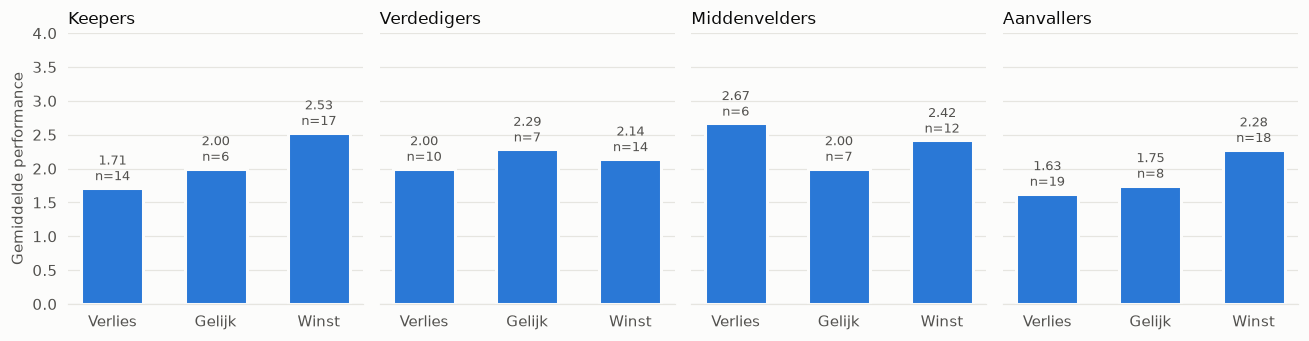

In [40]:
RESULT_LABELS = {-1: "Verlies", 0: "Gelijk", 1: "Winst"}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, group in zip(axes, GROUPS):
    df = reports[reports["questionnaire_position"].isin(POSITION_GROUPS[group])]
    summary = df.groupby("result")["performance"].agg(["mean", "count"]).reindex([-1, 0, 1])
    x = np.arange(3)
    ax.bar(x, summary["mean"], width=0.6, color=BLUE, edgecolor=SURFACE, linewidth=2)
    for xi, (mean, count) in zip(x, summary.itertuples(index=False)):
        if not np.isnan(mean):
            ax.text(xi, mean + 0.05, f"{mean:.2f}\nn={count:.0f}", ha="center", va="bottom", fontsize=8.5, color=INK_MUTED)
    ax.set_xticks(x, RESULT_LABELS.values())
    ax.set_title(group)
    ax.grid(axis="y")
    ax.spines["left"].set_visible(False)
axes[0].set_ylabel("Gemiddelde performance")
axes[0].set_ylim(0, 4)
fig.tight_layout()
plt.show()

## 4. Keepers in detail

De sterkste vraag voor uitkomstbias is: hangt het oordeel samen met de uitslag, ook als je rekening houdt met hoe goed de keeper keepte?
- **Goals prevented** meet het eigen aandeel van de keeper in de tegendoelpunten.
- **Doelpunten van de eigen ploeg** heeft de keeper niet in de hand. Voorspellen die het oordeel nog, naast goals prevented, dan wijst dat op uitkomstbias.

Beide modellen zijn OLS binnen scouts: de gemiddelden per scout zijn eraf. Dat blijft een kleine steekproef, die vooral van één scout komt.

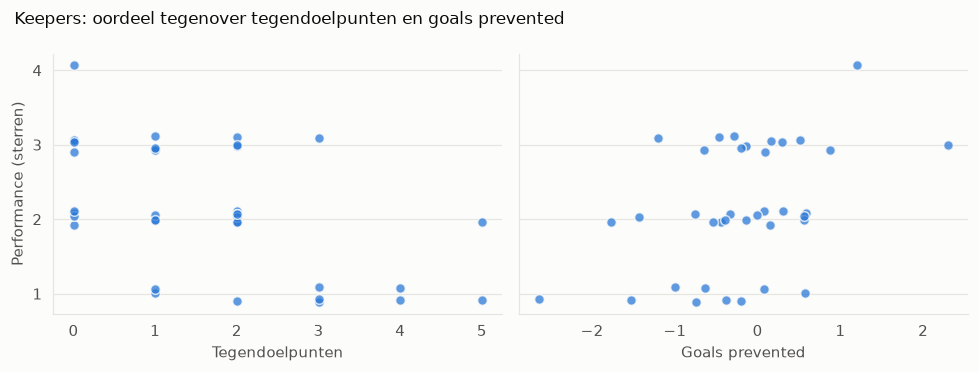

,mean,count
clean_sheet,,
tegendoelpunt(en),1.96,28
clean sheet,2.67,9


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, metric in zip(axes, ["goals_conceded", "goals_prevented"]):
    jitter = np.random.default_rng(42).uniform(-0.12, 0.12, len(keepers))
    ax.scatter(keepers[metric], keepers["performance"] + jitter, s=40, color=BLUE, alpha=0.75, edgecolor=SURFACE)
    ax.set_xlabel(LABELS[metric])
    ax.grid(axis="y")
axes[0].set_ylabel("Performance (sterren)")
axes[0].set_yticks([1, 2, 3, 4])
fig.suptitle("Keepers: oordeel tegenover tegendoelpunten en goals prevented", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

keepers.groupby("clean_sheet")["performance"].agg(["mean", "count"]).rename(index={0: "tegendoelpunt(en)", 1: "clean sheet"}).round(2)

**Performance per aantal tegendoelpunten.** Links het gemiddelde, rechts de verdeling van de sterren. Bij keepers loopt het oordeel duidelijk terug met elk extra tegendoelpunt.

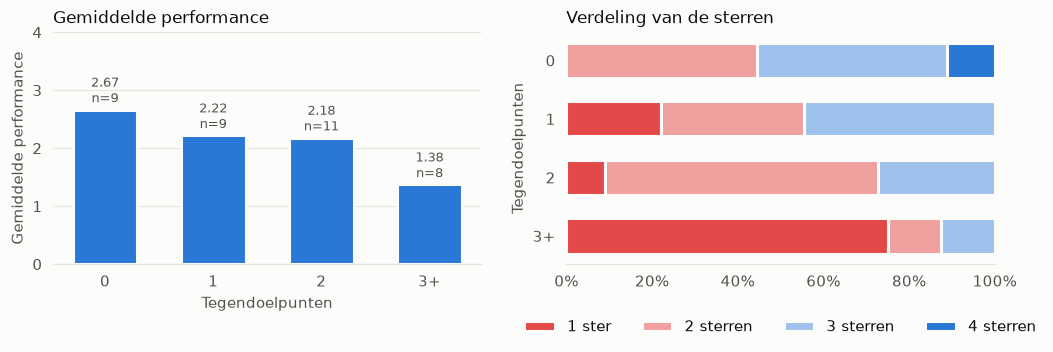

In [42]:
STAR_COLORS = ["#e34948", "#f0a09f", "#9fc2ec", "#2a78d6"]  # 1 tot 4 sterren
bins = pd.cut(keepers["goals_conceded"], [-0.5, 0.5, 1.5, 2.5, 99], labels=["0", "1", "2", "3+"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
summary = keepers.groupby(bins, observed=False)["performance"].agg(["mean", "count"])
x = np.arange(len(summary))
ax1.bar(x, summary["mean"], width=0.6, color=BLUE, edgecolor=SURFACE, linewidth=2)
for xi, (mean, count) in zip(x, summary.itertuples(index=False)):
    ax1.text(xi, mean + 0.05, f"{mean:.2f}\nn={count}", ha="center", va="bottom", fontsize=8.5, color=INK_MUTED)
ax1.set_xticks(x, summary.index)
ax1.set_xlabel("Tegendoelpunten")
ax1.set_ylabel("Gemiddelde performance")
ax1.set_ylim(0, 4)
ax1.grid(axis="y")
ax1.spines["left"].set_visible(False)
ax1.set_title("Gemiddelde performance")

shares = pd.crosstab(bins, keepers["performance"], normalize="index").reindex(columns=[1.0, 2.0, 3.0, 4.0], fill_value=0)
left = np.zeros(len(shares))
for stars, color in zip(shares.columns, STAR_COLORS):
    ax2.barh(np.arange(len(shares)), shares[stars], left=left, color=color, edgecolor=SURFACE, linewidth=2,
             height=0.6, label=f"{stars:.0f} ster" + ("ren" if stars > 1 else ""))
    left += shares[stars].to_numpy()
ax2.set_yticks(np.arange(len(shares)), shares.index)
ax2.set_ylabel("Tegendoelpunten")
ax2.invert_yaxis()
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.spines["left"].set_visible(False)
ax2.set_title("Verdeling van de sterren")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
fig.tight_layout()
plt.show()

In [43]:
import statsmodels.api as sm

k = keepers[keepers.groupby("scout_id")["scout_id"].transform("size") >= MIN_REPORTS_WITHIN_SCOUT]
cols = ["performance", "goals_prevented", "goals_for", "clean_sheet", "goals_conceded"]
kc = k[cols] - k.groupby("scout_id")[cols].transform("mean")

for predictors in [["goals_prevented", "goals_for"], ["goals_prevented", "clean_sheet"]]:
    fit = sm.OLS(kc["performance"], kc[predictors]).fit()
    print(f"performance ~ {' + '.join(predictors)}   (n = {len(kc)})")
    print(pd.DataFrame({"b": fit.params, "se": fit.bse, "p": fit.pvalues}).round(3), "\n")

performance ~ goals_prevented + goals_for   (n = 36)
                     b     se      p
goals_prevented  0.453  0.140  0.003
goals_for        0.116  0.075  0.134 

performance ~ goals_prevented + clean_sheet   (n = 36)
                    b     se      p
goals_prevented  0.37  0.153  0.021
clean_sheet      0.48  0.312  0.133 



## 5. Bevindingen

Cijfers uit de eerste uitvoering (23/11/2026). Ruw = Spearman, binnen = binnen scouts. Alleen de twee keeperresultaten voor de uitslag blijven overeind na correctie voor meerdere toetsen (q < 0.05). De rest is een aanwijzing, geen vaststelling.

**Keepers (n = 37, waarvan 31 van scout 22)**
- Het oordeel hangt duidelijk samen met de uitslag. Voor tegendoelpunten is ρ = −0.49 (binnen −0.57), voor het doelsaldo ρ = 0.51. Met een clean sheet is de gemiddelde performance 2.67, met tegendoelpunten 1.96.
- Goals prevented hangt ook samen met het oordeel (ρ = 0.37, binnen 0.49). Een deel van het verband met tegendoelpunten is dus gewoon de prestatie van de keeper zelf.
- Naast goals prevented voegen de doelpunten van de eigen ploeg (b = 0.12, p = 0.13) en een clean sheet (b = 0.48, p = 0.13) weinig zeker toe. De richting past bij uitkomstbias, maar met 36 rapporten is dat niet aan te tonen.
- Ook **potential** daalt bij meer tegendoelpunten (binnen −0.55), terwijl potential niet van één wedstrijd zou mogen afhangen.
- Het passpercentage hangt licht negatief samen met het oordeel (potential ρ = −0.42). Het zegt weinig over keepers, omdat lange ballen vaker mislukken.

**Verdedigers (n = 31)**
- Er is geen verband met een clean sheet (ρ = −0.11).
- Binnen scouts gaat het oordeel licht omlaag bij meer tegendoelpunten (−0.39, p = 0.04) en omhoog bij een beter resultaat (0.36, p = 0.06).
- Het passpercentage hangt het duidelijkst samen met performance (ρ = 0.47, binnen 0.44).

**Middenvelders (n = 25)**
- Het duelpercentage (ρ = 0.46) en het passpercentage (ρ = 0.37) hangen positief samen met performance.
- De uitslag speelt geen rol.

**Aanvallers (n = 45)**
- Performance hangt meer samen met het resultaat (ρ = 0.39) en het doelsaldo (0.42) dan met eigen doelpunten (0.06). Assists zitten daartussen (0.34).
- Binnen scouts wordt het verband met de uitslag kleiner (0.21-0.25). Een deel komt dus van verschillen tussen scouts, en niet van wedstrijd tot wedstrijd.

## 6. Kanttekeningen

- **Kleine aantallen per groep.** Een correlatie van 0.3 is bij 30 rapporten nauwelijks van nul te onderscheiden.
- **Weinig scouts bij keepers.** De keeperresultaten komen voor het grootste deel van één scout (scout 22).
- **Positie volgens de vragenlijst.** De groepen zijn ingedeeld op de vragenlijst die de scout koos (`questionnaire_position`), niet op de positie in de opstelling.
- **Succespercentages zijn ruw.** Ze houden geen rekening met de moeilijkheid van de actie, en een minimum aantal pogingen per wedstrijd zorgt ervoor dat niet elke speler een waarde heeft.
- **Assists zijn afgeleid.** Een assist is hier de laatste geslaagde pass naar de doelpuntenmaker in hetzelfde balbezit. Een pass die afgeweerd wordt en dan toch bij de schutter komt, telt niet.
- **Samenhang, geen oorzaak.** Een goede keeper krijgt minder doelpunten. Een verband met tegendoelpunten is dus pas bias als het blijft bestaan naast goals prevented (sectie 4).